# 02 — Exploratory Data Analysis (EDA)

Statistical distribution analysis, Mann-Whitney U tests, Spearman rank correlations, and hepatology-domain interpretation on the deduplicated ILPD cohort (`n=570`).

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from liver_disease.config import FIGURES_DIR, REPORTS_DIR
from liver_disease.utils.io import load_json

eda = load_json(REPORTS_DIR / 'eda_summary.json')
print('Raw rows:', eda['raw_rows'], '| Deduplicated rows:', eda['deduplicated_rows'])
print('Gender chi-square test:', eda['gender_chi2_test'])
print('High collinearity pairs (|Spearman r| >= 0.70):')
display(pd.DataFrame(eda['high_collinearity_pairs_spearman_gt_0_7']))

Raw rows: 583 | Deduplicated rows: 570
Gender chi-square test: {'chi2_statistic': 3.1212, 'p_value': 0.07727778295019577, 'dof': 1, 'disease_rate_male_pct': 73.26, 'disease_rate_female_pct': 65.0}
High collinearity pairs (|Spearman r| >= 0.70):


,feature_1,feature_2,spearman_r
0,TB,DB,0.9584
1,Sgpt,Sgot,0.7719
2,TP,ALB,0.7782
3,ALB,A/G Ratio,0.7535


In [2]:
tests_df = pd.DataFrame(eda['feature_statistical_tests_mann_whitney']).T
display(tests_df.sort_values('p_value'))

,disease_median,disease_iqr,no_disease_median,no_disease_iqr,mann_whitney_u,p_value,spearman_r_with_disease,rank_biserial_effect
TB,1.4,2.875,0.80,0.40,46662.0,4.680861e-14,0.3161,-0.4016
Sgot,51.0,78.250,29.00,22.00,46474.0,1.299284e-13,0.3105,-0.3960
DB,0.5,1.600,0.20,0.10,46161.5,1.582710e-13,0.3094,-0.3866
Sgpt,40.5,50.750,27.00,17.25,45631.0,4.112483e-12,0.2907,-0.3706
Alkphos,229.0,133.000,186.50,50.00,44929.5,6.234177e-11,0.2741,-0.3496
A/G Ratio,0.9,0.400,1.00,0.30,24531.0,2.822010e-06,-0.1970,0.2504
ALB,3.0,1.175,3.45,1.10,25928.0,3.465500e-05,-0.1736,0.2212
Age,46.0,24.000,41.00,27.50,38787.0,2.014676e-03,0.1295,-0.1651
TP,6.6,1.475,6.65,1.40,31787.5,3.978895e-01,-0.0355,0.0452


01_target_and_gender_distribution.png


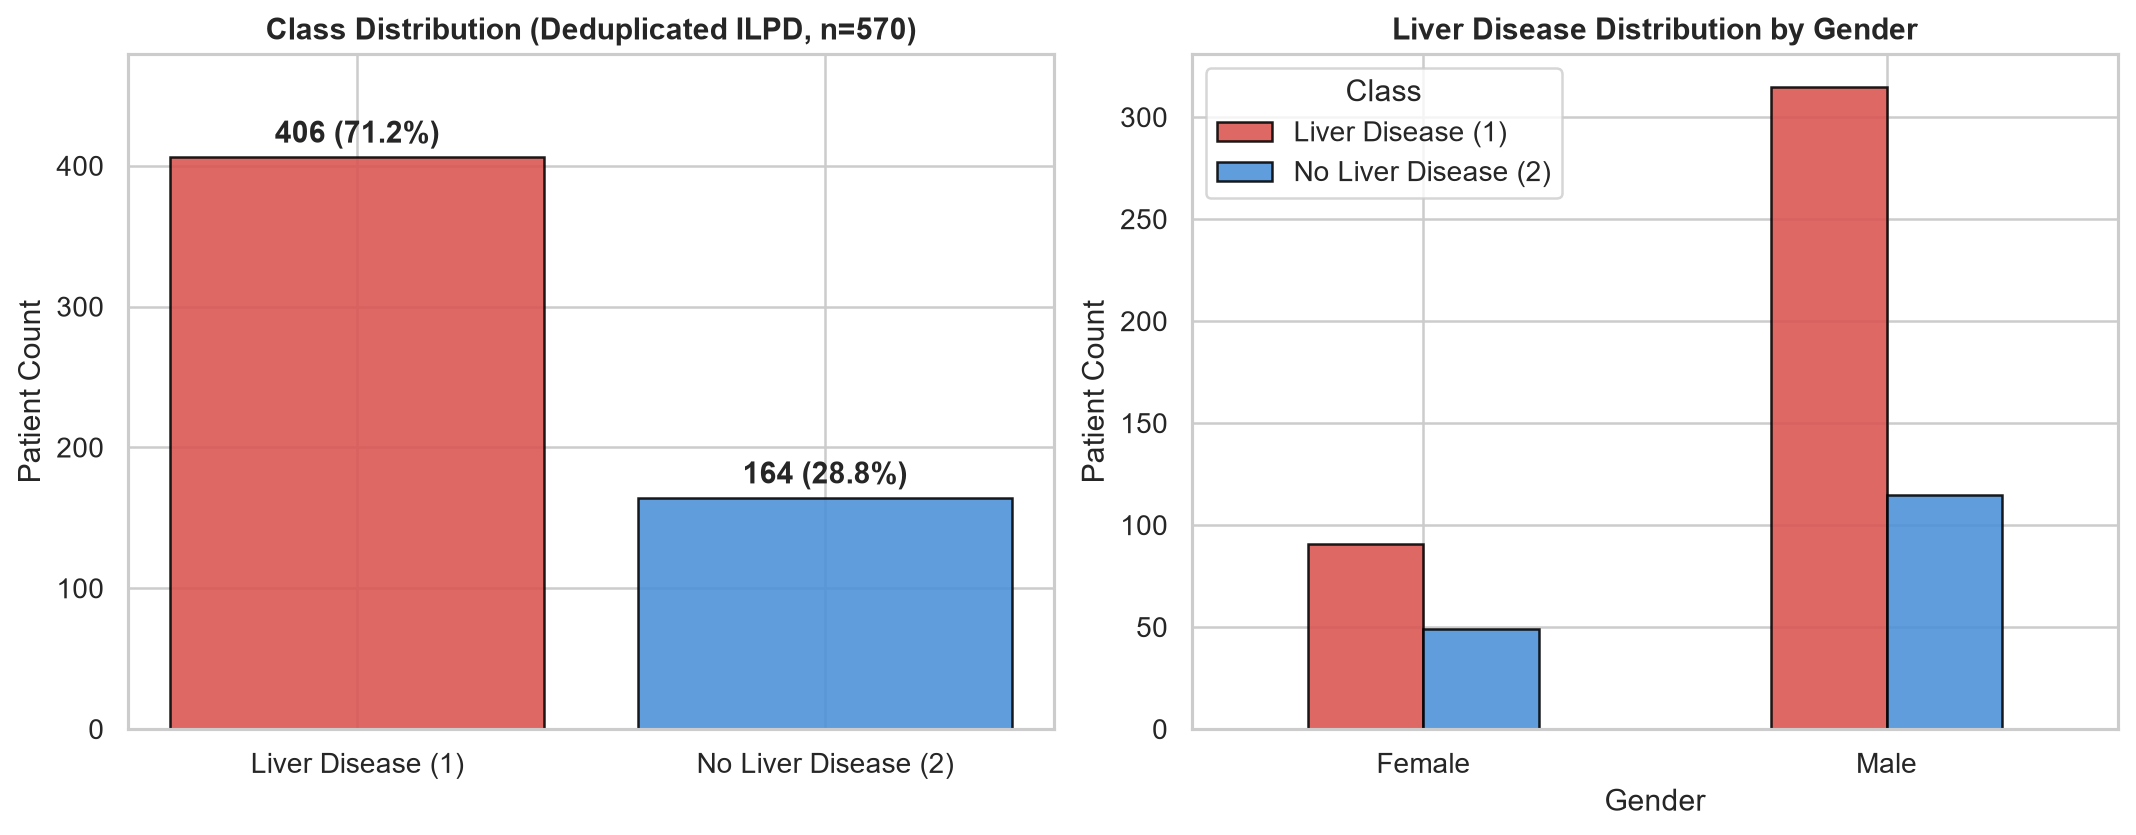

02_numeric_distributions_by_class.png


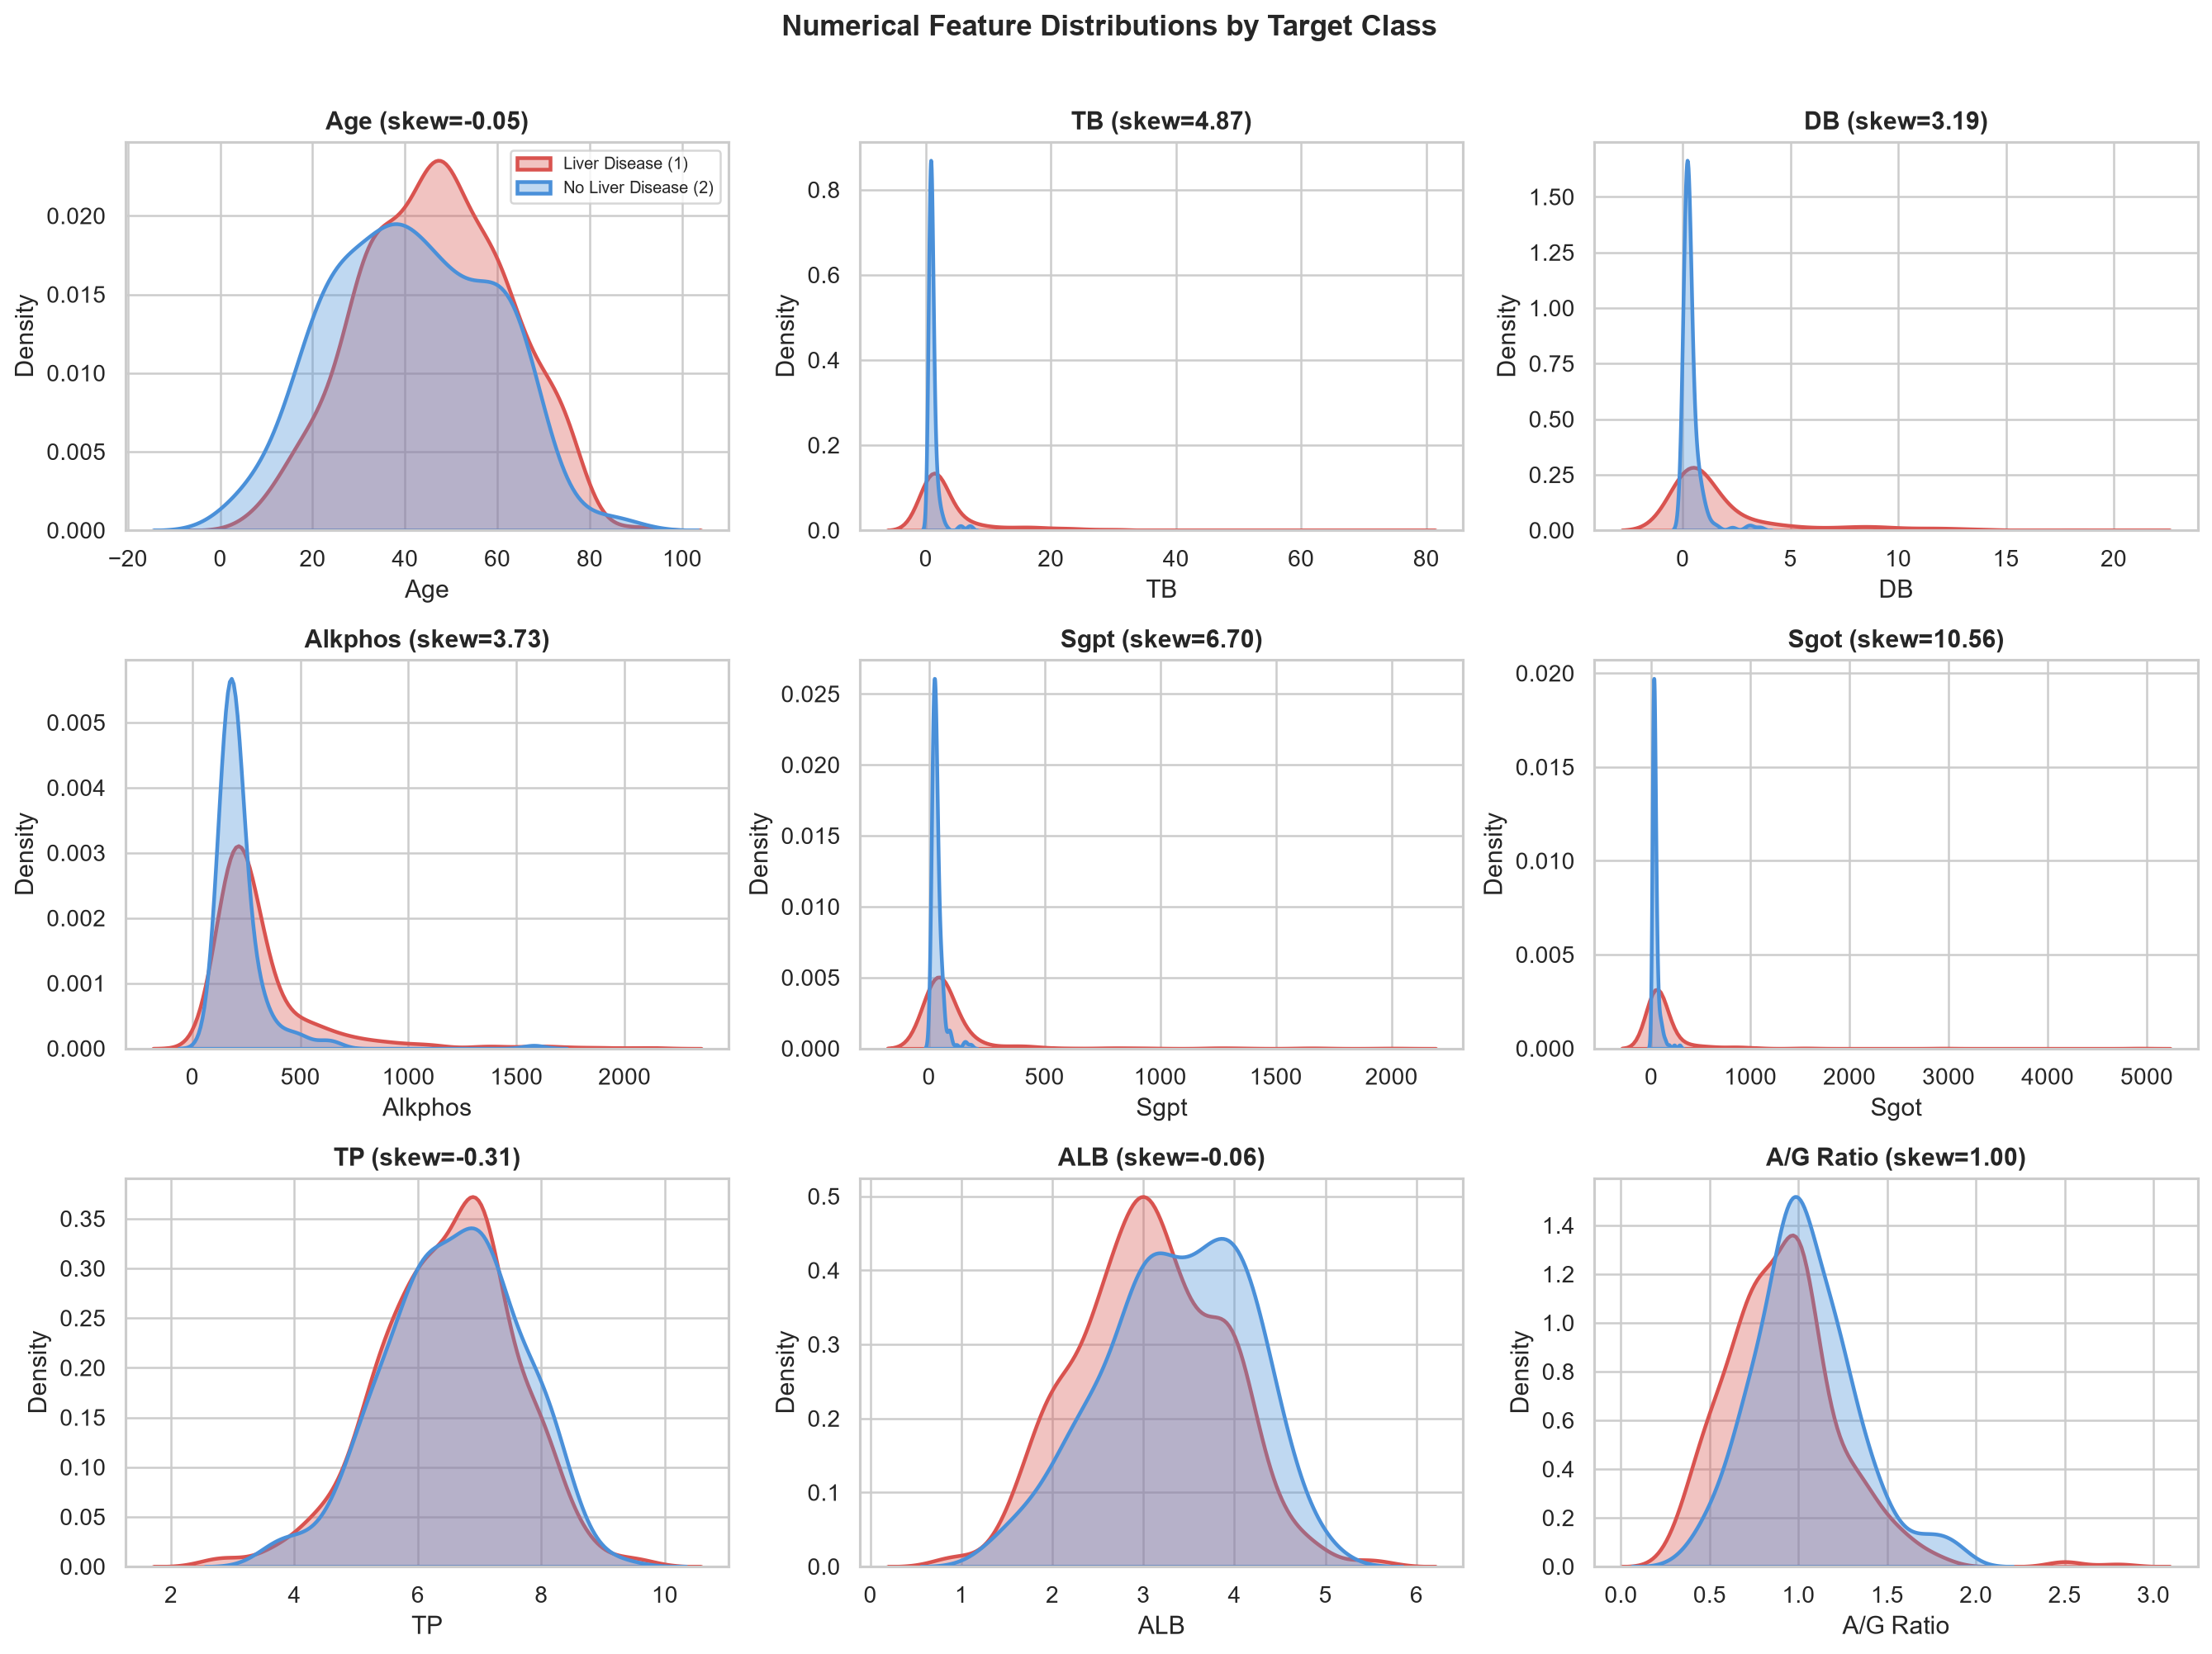

03_boxplots_and_outliers.png


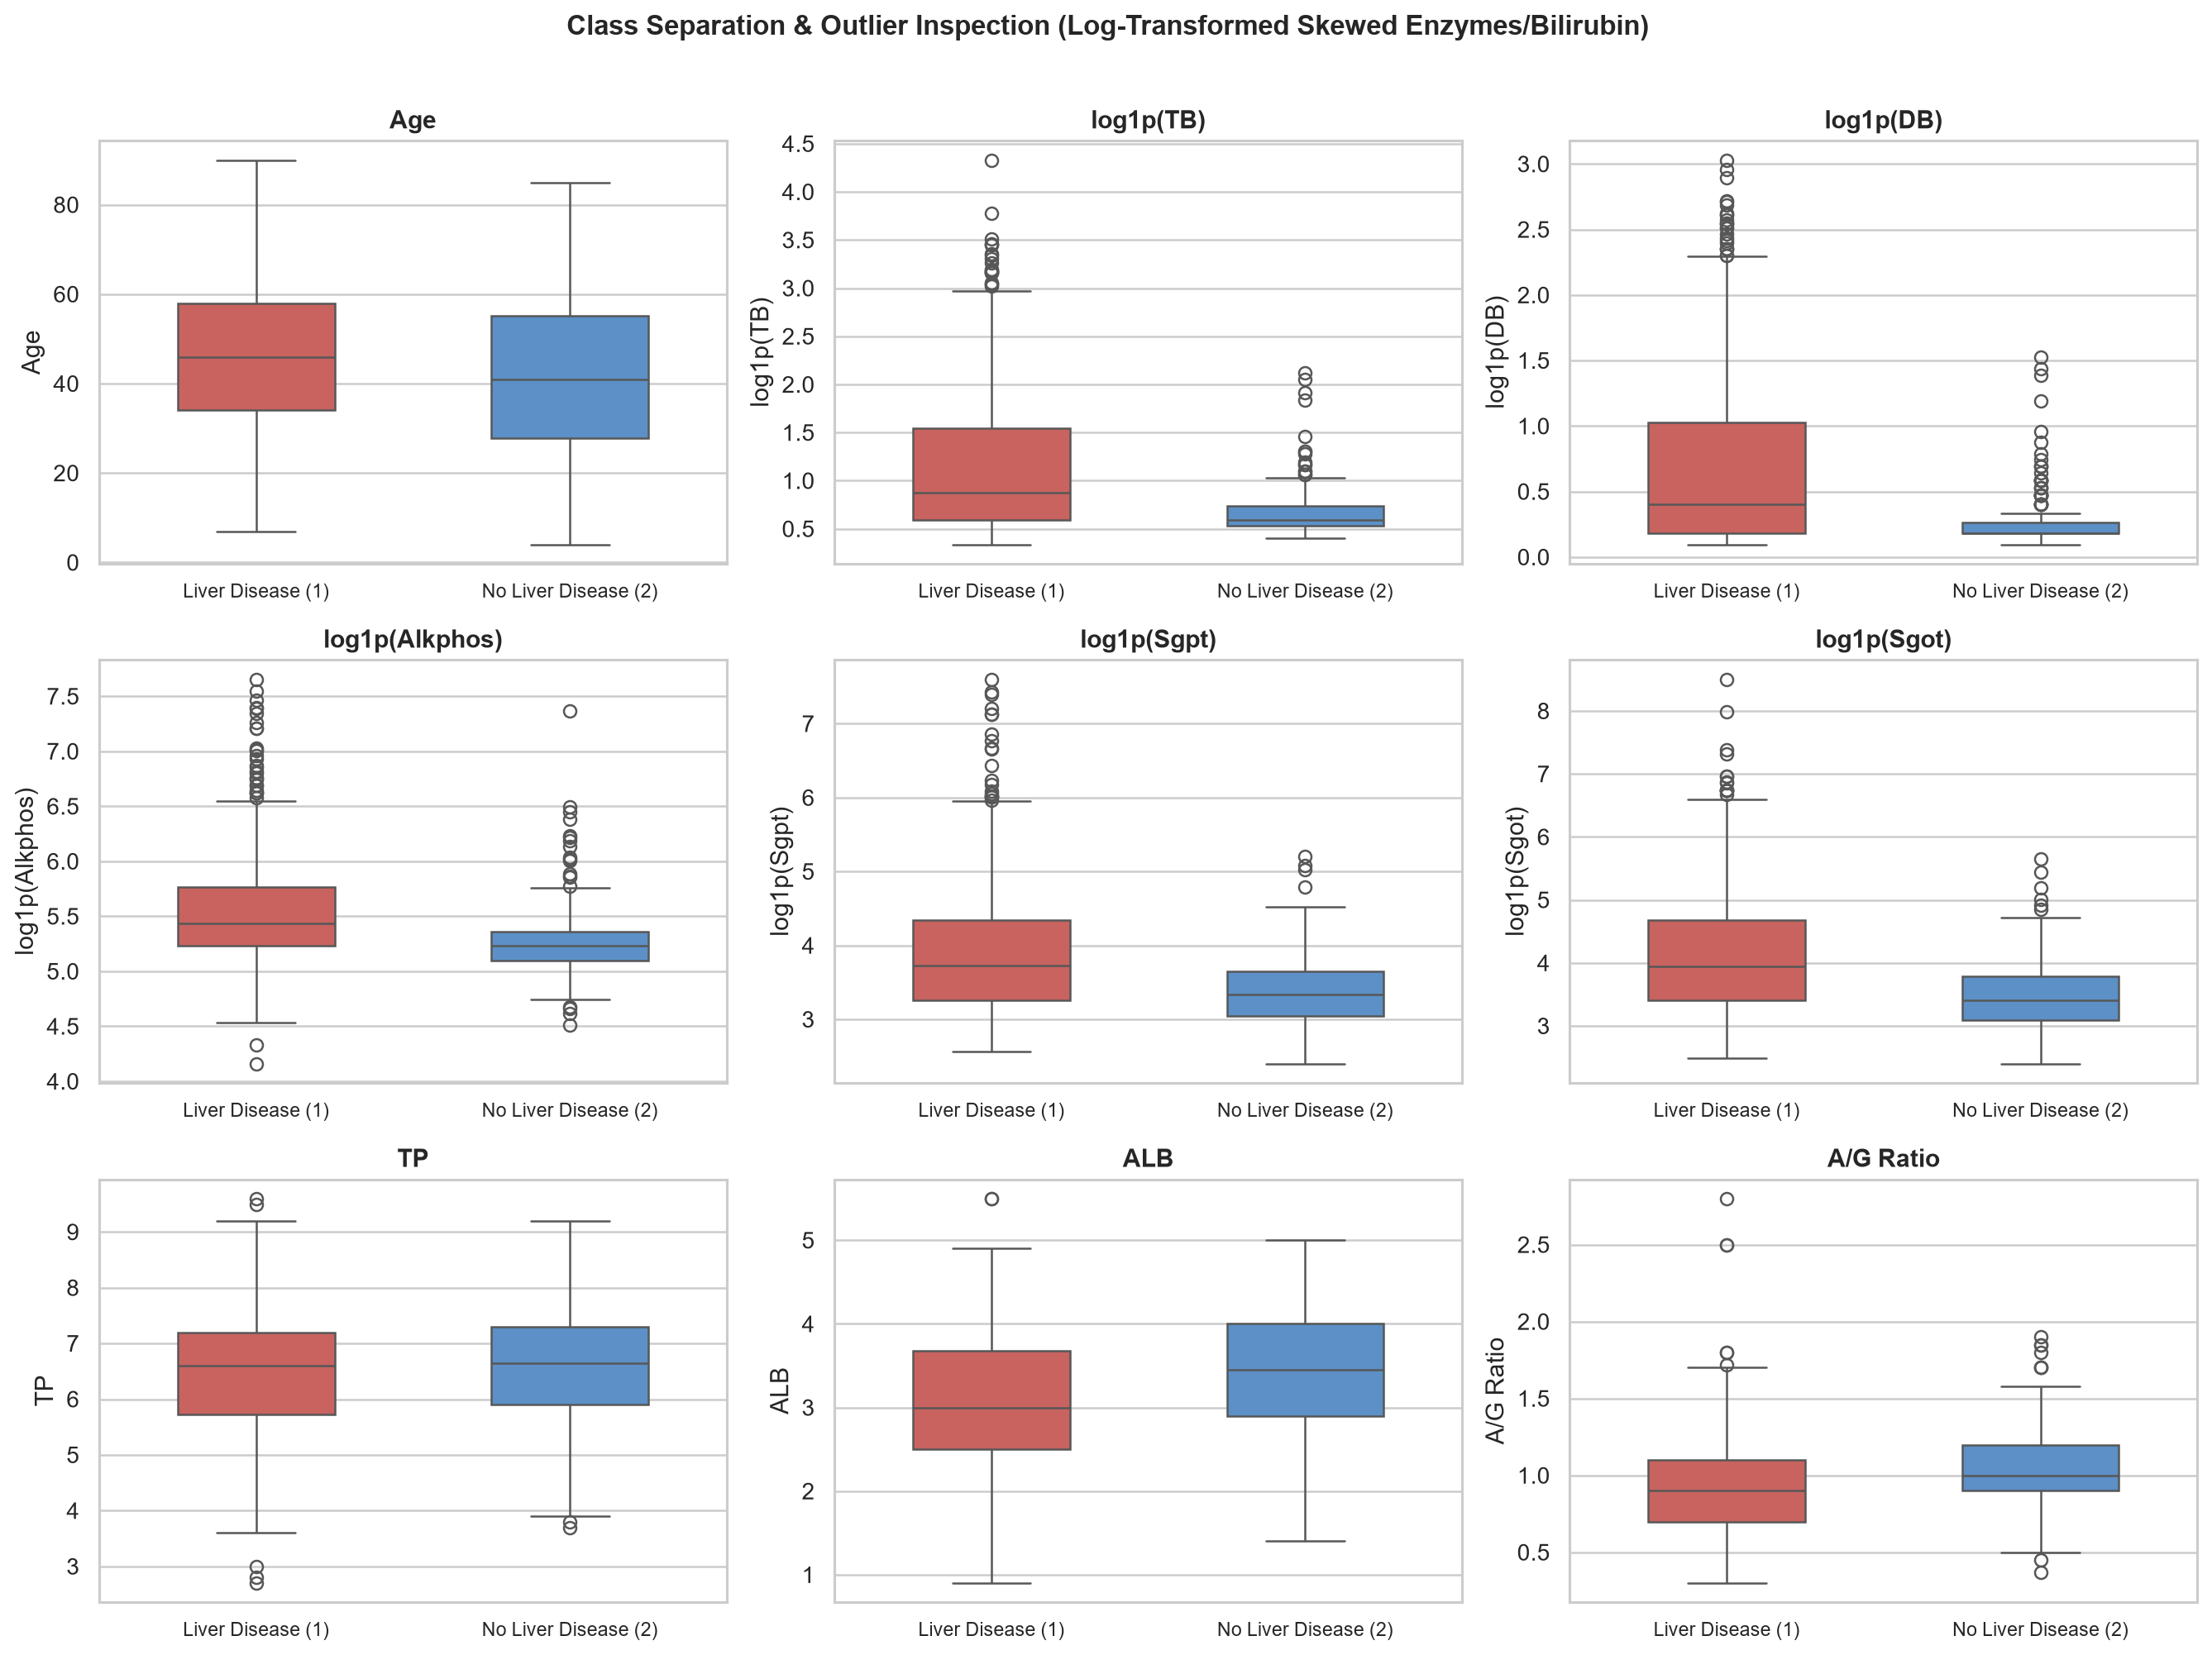

04_spearman_correlation_heatmap.png


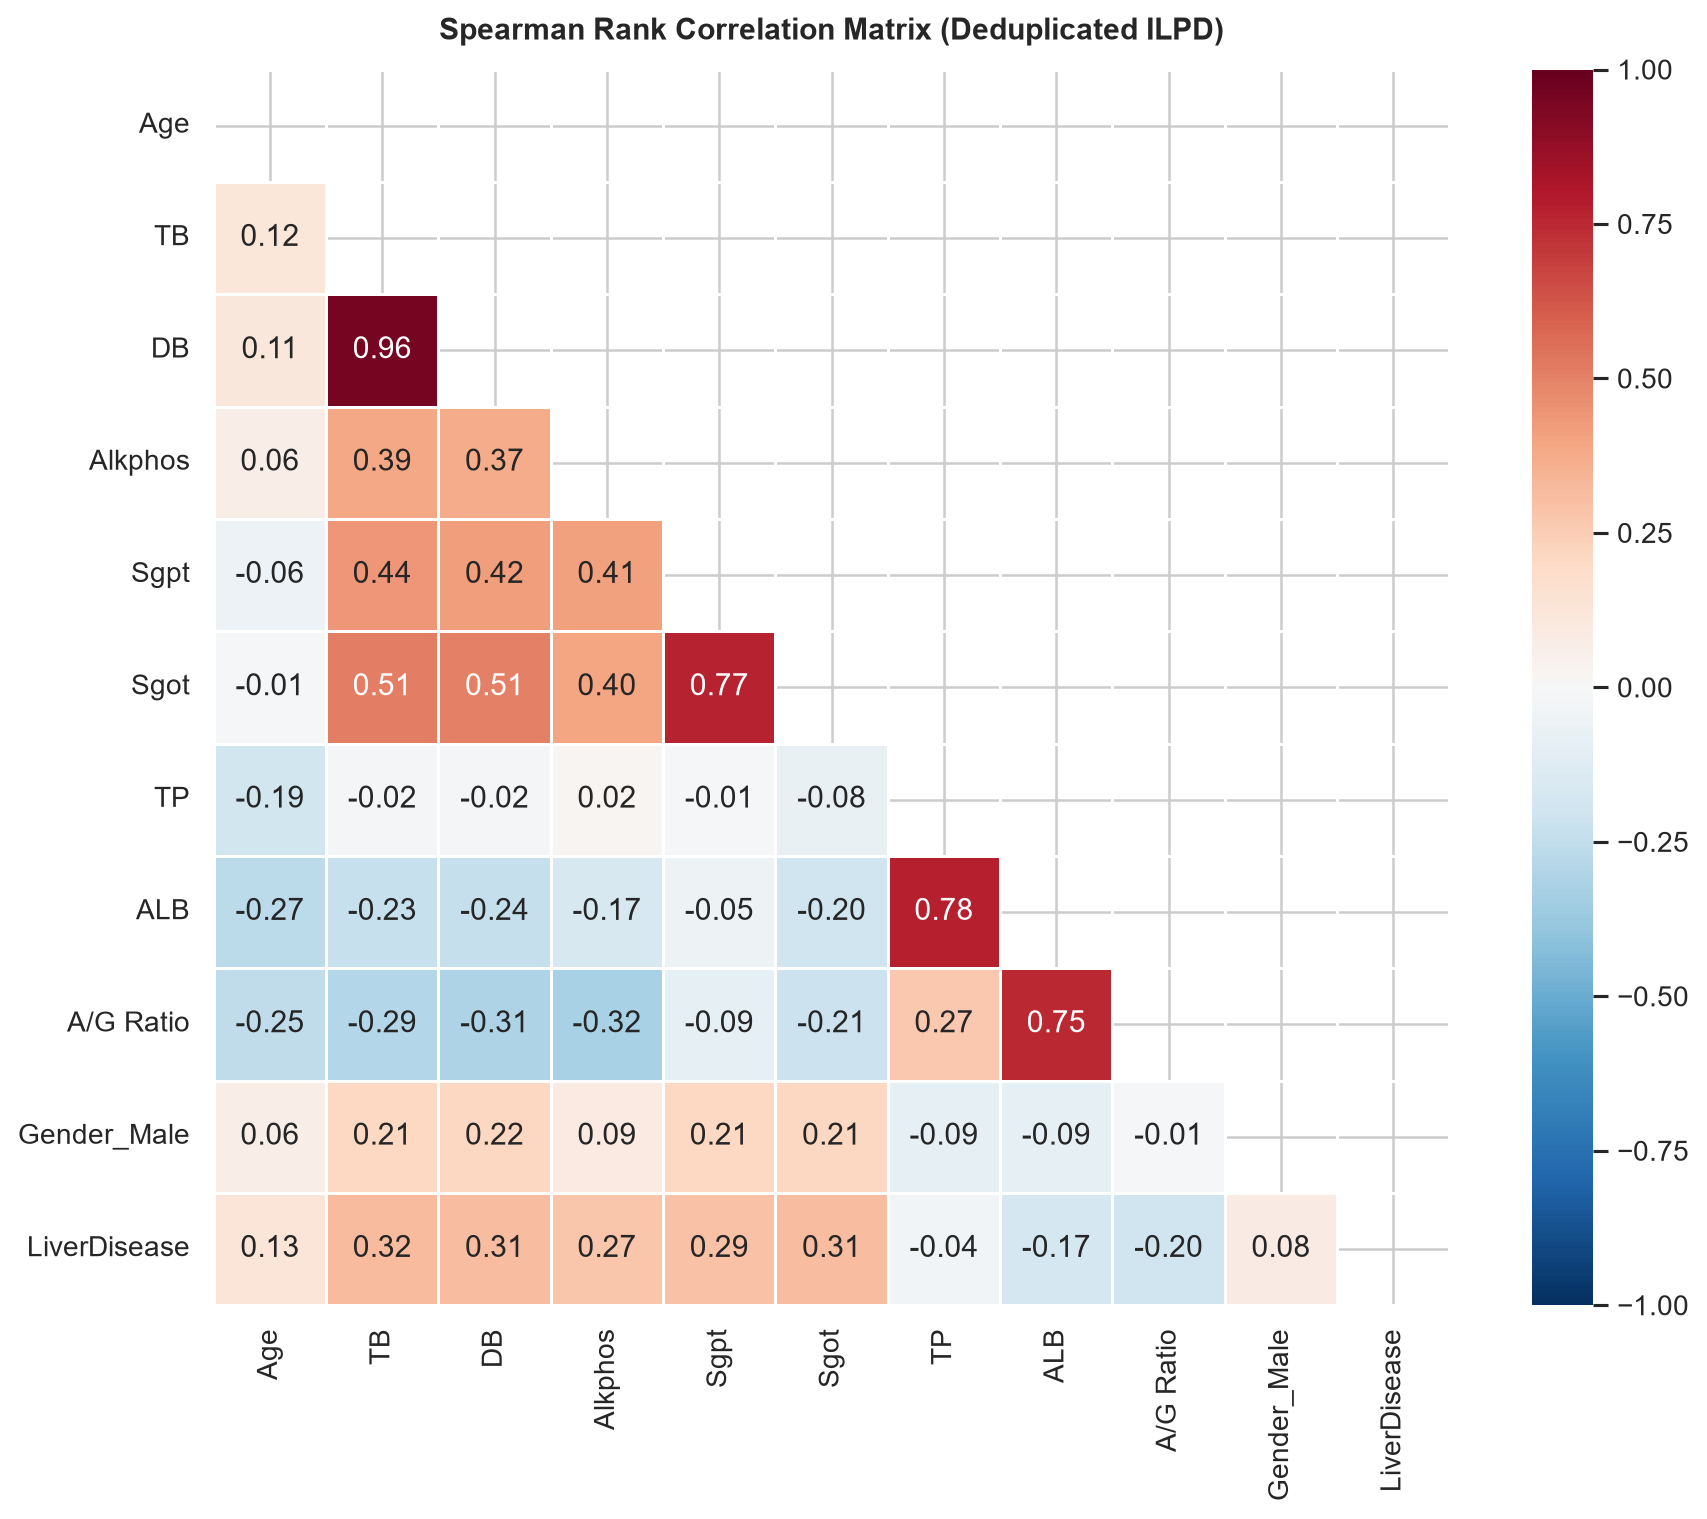

In [3]:
for img_name in [
    '01_target_and_gender_distribution.png',
    '02_numeric_distributions_by_class.png',
    '03_boxplots_and_outliers.png',
    '04_spearman_correlation_heatmap.png',
]:
    print(img_name)
    display(Image(filename=str(FIGURES_DIR / img_name)))